# Task 2 – Customer Segmentation (RFM + K-Means)

**Thiranex Data Analytics Internship · Aditya Chauhan**

**Goal:** group customers by their buying behaviour so the business can target each group with the right action.

**Approach**
1. Build one row per customer with **RFM** features: **R**ecency (days since last order), **F**requency (number of orders), **M**onetary (total spend)
2. Log-transform and scale the features, then pick the number of clusters with the **elbow method** and **silhouette score**
3. Cluster with **K-Means** and give each cluster a business name
4. Profile each segment: value, purchase patterns, category preferences, discount behaviour
5. Turn the results into targeted recommendations

**Dataset:** `retail_sales_data.csv` (same data as Task 1), with order-level retail sales from Jan 2023 to Oct 2026.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", font_scale=1.0)
pd.set_option("display.float_format", "{:,.2f}".format)
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("../retail_sales_data.csv", parse_dates=["Order Date"])
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

5,947 rows x 16 columns


,Order ID,Order Date,Customer ID,Customer Name,Segment,City,State,Region,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit
0,ORD-100016,2023-01-01,CUS-0627,Pooja Agarwal,Consumer,Kochi,Kerala,South,Office Supplies,Art,Colour Pencil Kit,3,515,0.10,"1,390.50",514.76
1,ORD-100030,2023-01-01,CUS-0492,Ishaan Das,Corporate,Hyderabad,Telangana,South,Furniture,Tables,Folding Table,7,4424,0.20,"24,774.40","-2,900.99"
2,ORD-100004,2023-01-02,CUS-0241,Nikhil Chauhan,Consumer,Hyderabad,Telangana,South,Office Supplies,Art,Marker Set,5,376,0.10,"1,692.00",606.85
3,ORD-100026,2023-01-02,CUS-0068,Meera Kulkarni,Consumer,Pune,Maharashtra,West,Furniture,Chairs,Ergonomic Office Chair,2,8486,0.10,"15,274.80","3,430.79"
4,ORD-100046,2023-01-02,CUS-0094,Priya Mehta,Consumer,Ahmedabad,Gujarat,West,Office Supplies,Paper,A4 Paper Ream,5,322,0.00,"1,610.00",643.27


## 1. Data quality check

In [3]:
print("Missing values per column:", int(df.isna().sum().sum()))
print("Duplicate rows:            ", int(df.duplicated().sum()))
print("Duplicate Order IDs:       ", int(df["Order ID"].duplicated().sum()))
print("Date range:                ", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
print("Unique customers:          ", df["Customer ID"].nunique())
print("Negative sales rows:       ", int((df["Sales"] <= 0).sum()))

Missing values per column: 0
Duplicate rows:             0
Duplicate Order IDs:        0
Date range:                 2023-01-01 to 2026-10-31
Unique customers:           662
Negative sales rows:        0


The data is clean: no missing values, duplicates or invalid sales, so we can go straight to feature engineering.

## 2. Build customer-level features

The snapshot date is the day after the last order in the data. Recency is measured from that date.

Besides R, F and M, I also calculate behaviour features (average order value, discount use, profit margin, category mix). These are **not** used for clustering, only for **profiling** the segments afterwards.

In [4]:
snapshot = df["Order Date"].max() + pd.Timedelta(days=1)

cust = df.groupby("Customer ID").agg(
    Recency=("Order Date", lambda s: (snapshot - s.max()).days),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum"),
    Profit=("Profit", "sum"),
    AvgDiscount=("Discount", "mean"),
    Units=("Quantity", "sum"),
    CustomerType=("Segment", "first"),
    Region=("Region", "first"),
)
cust["AvgOrderValue"] = cust["Monetary"] / cust["Frequency"]
cust["ProfitMargin"] = cust["Profit"] / cust["Monetary"]

# share of each customer's spend going to each category
cat_share = df.pivot_table(index="Customer ID", columns="Category", values="Sales", aggfunc="sum", fill_value=0)
cat_share = cat_share.div(cat_share.sum(axis=1), axis=0)
cust = cust.join(cat_share.add_prefix("Share_"))

print(f"{len(cust)} customers")
cust.head()

662 customers


,Recency,Frequency,Monetary,Profit,AvgDiscount,Units,CustomerType,Region,AvgOrderValue,ProfitMargin,Share_Furniture,Share_Office Supplies,Share_Technology
Customer ID,,,,,,,,,,,,,
CUS-0001,793,4,"25,250.70","5,107.34",0.04,23,Corporate,South,"6,312.68",0.20,0.63,0.37,0.00
CUS-0002,55,1,"1,864.80",270.97,0.10,7,Home Office,West,"1,864.80",0.15,0.00,1.00,0.00
CUS-0003,252,9,"24,360.90","6,710.65",0.11,22,Consumer,East,"2,706.77",0.28,0.35,0.12,0.53
CUS-0004,802,8,"26,123.25","8,811.59",0.06,17,Consumer,South,"3,265.41",0.34,0.48,0.36,0.15
CUS-0005,116,21,"190,711.15","54,005.59",0.08,73,Corporate,North,"9,081.48",0.28,0.14,0.31,0.55


In [5]:
cust[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,662.00,662.00,662.00
mean,326.05,8.98,"54,475.55"
std,357.90,12.63,"80,370.35"
min,1.00,1.00,122.40
25%,37.00,2.00,"8,450.15"
50%,156.00,5.00,"25,561.15"
75%,577.00,11.00,"72,119.29"
max,"1,397.00",136.00,"832,680.30"


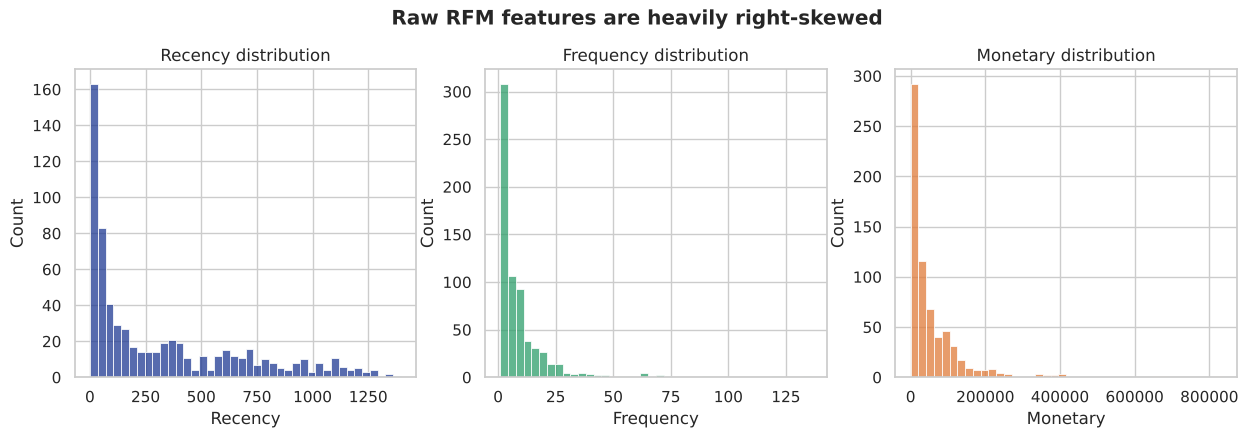

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ["Recency", "Frequency", "Monetary"], ["#1F3A93", "#2E9E6B", "#E07B39"]):
    sns.histplot(cust[col], bins=40, ax=ax, color=color)
    ax.set_title(f"{col} distribution")
plt.suptitle("Raw RFM features are heavily right-skewed", fontweight="bold", y=1.03)
plt.show()

All three features are **strongly right-skewed**: a few customers order very often and spend a lot. K-Means uses distances, so these outliers would dominate the clusters.

To fix this, I apply `log1p` to compress the long tail, then `StandardScaler` so that R, F and M carry equal weight.

## 3. Preprocessing

In [7]:
rfm = cust[["Recency", "Frequency", "Monetary"]]
rfm_log = np.log1p(rfm)
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)

pd.DataFrame(X, columns=rfm.columns).describe().loc[["mean", "std"]].round(2)

,Recency,Frequency,Monetary
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00


## 4. Choosing the number of clusters (k)

I try k = 2 to 8 and compare:
- **Inertia** (within-cluster sum of squares): look for the "elbow" where adding clusters stops helping much
- **Silhouette score** (−1 to 1): how well separated the clusters are, where higher is better

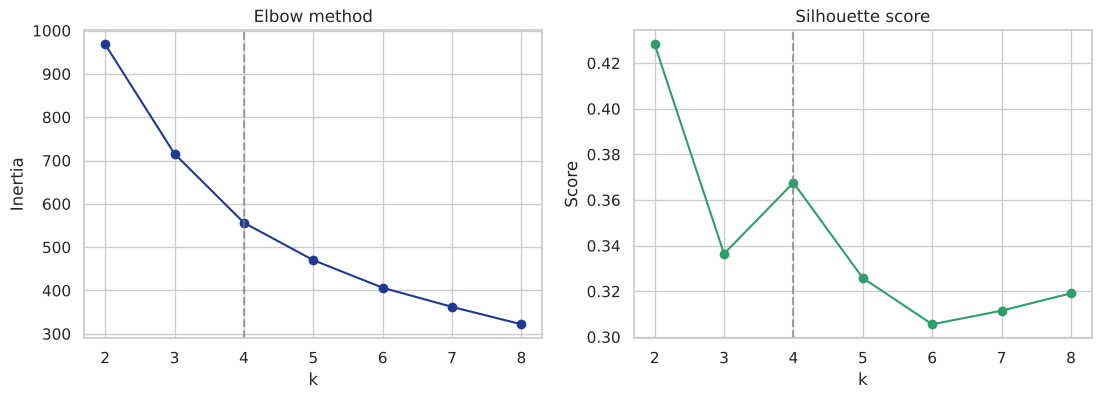

,Inertia,Silhouette
k,,
2,968.35,0.43
3,715.61,0.34
4,556.39,0.37
5,470.02,0.33
6,406.30,0.31
7,362.10,0.31
8,321.93,0.32


In [8]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertia, "o-", color="#1F3A93"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(ks, silhouette, "o-", color="#2E9E6B"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Score")
for ax in axes: ax.axvline(4, ls="--", color="grey", alpha=.7)
plt.show()

pd.DataFrame({"k": list(ks), "Inertia": inertia, "Silhouette": silhouette}).set_index("k").round(3)

**Choosing k = 4**
- k = 2 has the highest silhouette, but it only splits customers into "good" and "bad", which is too coarse to act on.
- After k = 2, the silhouette score **peaks at k = 4**, and the elbow curve flattens around the same point.
- Four clusters also map cleanly onto well-known RFM segments, so the result is easy for a business to use.

## 5. K-Means clustering (k = 4)

In [9]:
kmeans = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE)
cust["Cluster"] = kmeans.fit_predict(X)

cust.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].median()

,Recency,Frequency,Monetary
Cluster,,,
0,330.00,6.00,"37,069.40"
1,621.00,1.00,"5,734.00"
2,44.00,3.00,"14,018.50"
3,25.50,17.00,"103,790.67"


### Naming the clusters

K-Means only outputs numbers (0–3), so I assign business names using each cluster's median R, F and M. The rules below work whatever number K-Means gives each cluster:
- **Champions**: highest spend; ordered recently and often
- **Lost / Hibernating**: longest time since last order; usually bought only once or twice
- **New / Promising**: bought recently but only a few times so far
- **At Risk**: used to buy regularly but haven't ordered in many months

In [10]:
med = cust.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].median()
names = {}
names[med["Monetary"].idxmax()] = "Champions"
rest = med.drop(index=list(names))
names[rest["Recency"].idxmax()] = "Lost / Hibernating"
rest = rest.drop(index=rest["Recency"].idxmax())
names[rest["Recency"].idxmin()] = "New / Promising"
names[rest["Recency"].idxmax()] = "At Risk"
cust["SegmentName"] = cust["Cluster"].map(names)

ORDER = ["Champions", "At Risk", "New / Promising", "Lost / Hibernating"]
PALETTE = {"Champions": "#2E9E6B", "At Risk": "#E07B39", "New / Promising": "#1F77B4", "Lost / Hibernating": "#8C8C8C"}

profile = cust.groupby("SegmentName").agg(
    Customers=("Recency", "size"),
    Median_Recency_days=("Recency", "median"),
    Median_Orders=("Frequency", "median"),
    Median_Spend=("Monetary", "median"),
    Total_Revenue=("Monetary", "sum"),
    Avg_Order_Value=("AvgOrderValue", "mean"),
    Avg_Discount=("AvgDiscount", "mean"),
    Total_Profit=("Profit", "sum"),
).reindex(ORDER)
profile["% Customers"] = profile["Customers"] / profile["Customers"].sum() * 100
profile["% Revenue"] = profile["Total_Revenue"] / profile["Total_Revenue"].sum() * 100
profile["Profit_Margin_%"] = profile["Total_Profit"] / profile["Total_Revenue"] * 100
profile.round(1)

,Customers,Median_Recency_days,Median_Orders,Median_Spend,Total_Revenue,Avg_Order_Value,Avg_Discount,Total_Profit,% Customers,% Revenue,Profit_Margin_%
SegmentName,,,,,,,,,,,
Champions,170,25.50,17.00,"103,790.70","23,440,086.00","6,527.30",0.10,"5,186,571.60",25.70,65.00,22.10
At Risk,190,330.00,6.00,"37,069.40","9,350,631.60","6,860.60",0.10,"1,996,974.60",28.70,25.90,21.40
New / Promising,109,44.00,3.00,"14,018.50","1,875,184.70","5,576.60",0.10,"404,499.70",16.50,5.20,21.60
Lost / Hibernating,193,621.00,1.00,"5,734.00","1,396,912.30","4,782.50",0.10,"342,252.20",29.20,3.90,24.50


## 6. Visualising the segments

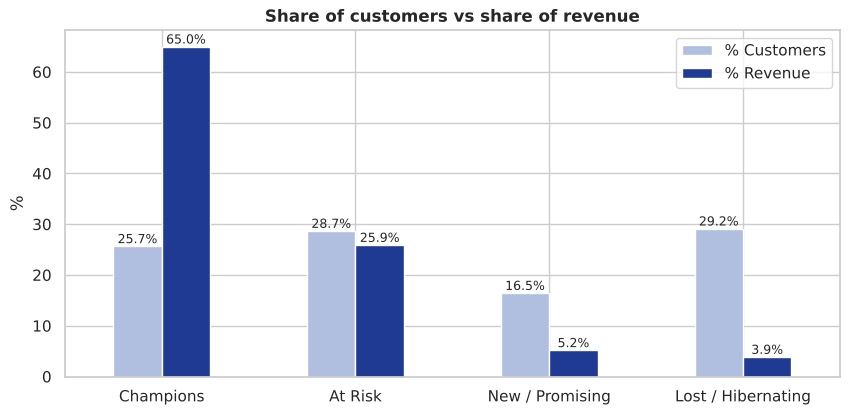

In [11]:
share = profile[["% Customers", "% Revenue"]]
ax = share.plot(kind="bar", figsize=(10, 4.5), color=["#B0BEDF", "#1F3A93"], rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", fontsize=9)
ax.set_title("Share of customers vs share of revenue", fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("%")
plt.show()

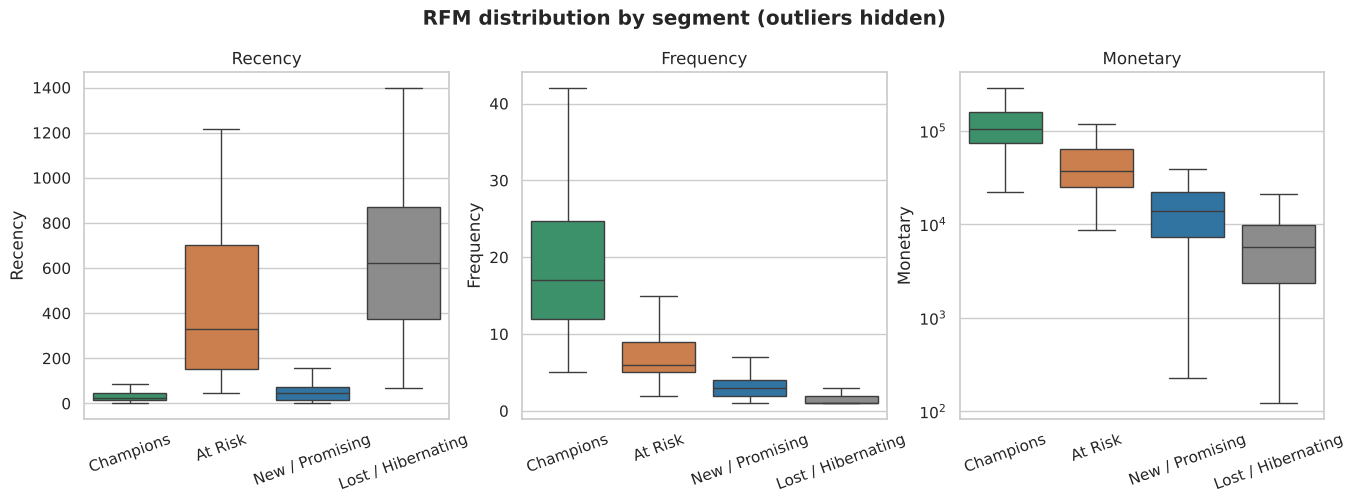

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=cust, x="SegmentName", y=col, order=ORDER, hue="SegmentName", palette=PALETTE, legend=False, ax=ax, showfliers=False)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
axes[2].set_yscale("log")
plt.suptitle("RFM distribution by segment (outliers hidden)", fontweight="bold", y=1.02)
plt.show()

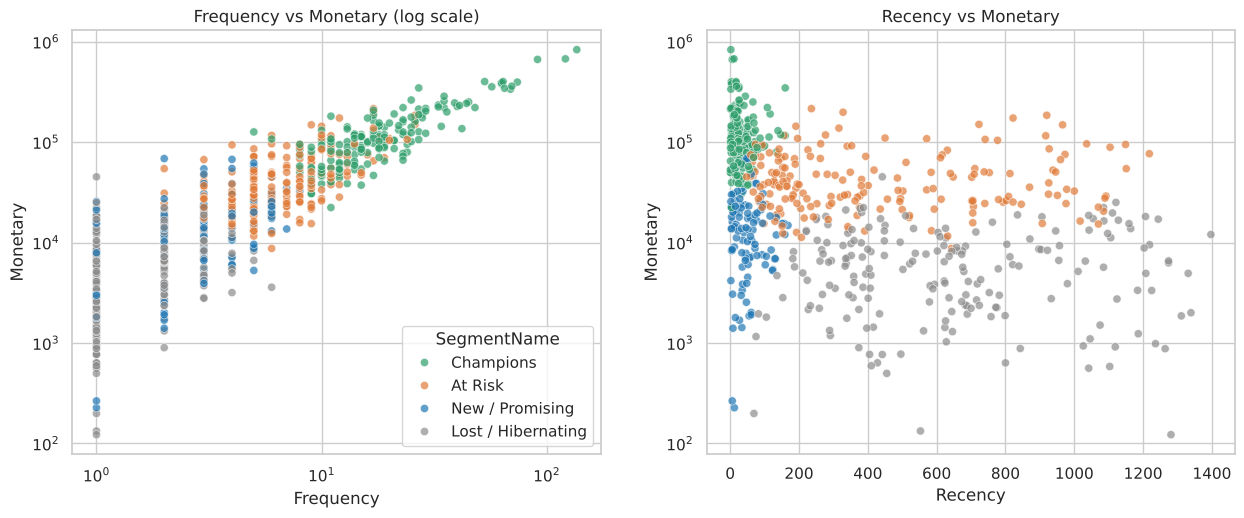

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=cust, x="Frequency", y="Monetary", hue="SegmentName", hue_order=ORDER, palette=PALETTE, alpha=.7, s=35, ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Frequency vs Monetary (log scale)")
sns.scatterplot(data=cust, x="Recency", y="Monetary", hue="SegmentName", hue_order=ORDER, palette=PALETTE, alpha=.7, s=35, ax=axes[1], legend=False)
axes[1].set(yscale="log", title="Recency vs Monetary")
plt.show()

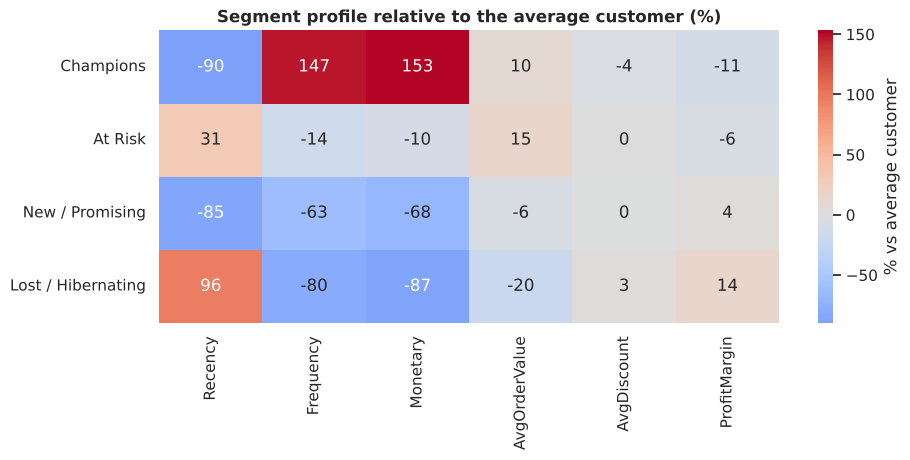

In [14]:
# How each segment compares with the average customer (+50% = 50% above average)
# Note: for Recency, higher = longer since last order (worse)
rel = cust.groupby("SegmentName")[["Recency", "Frequency", "Monetary", "AvgOrderValue", "AvgDiscount", "ProfitMargin"]].mean()
rel = (rel / cust[rel.columns].mean() - 1).reindex(ORDER) * 100
plt.figure(figsize=(10, 3.8))
sns.heatmap(rel, annot=True, fmt=".0f", cmap="coolwarm", center=0, cbar_kws={"label": "% vs average customer"})
plt.title("Segment profile relative to the average customer (%)", fontweight="bold"); plt.ylabel("")
plt.show()

## 7. Purchase patterns and customer preferences

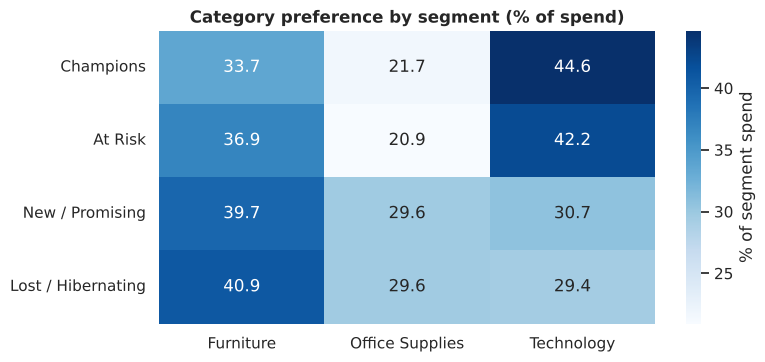

In [15]:
cat_cols = [c for c in cust.columns if c.startswith("Share_")]
seg_cat = df.merge(cust[["SegmentName"]], left_on="Customer ID", right_index=True) \
            .pivot_table(index="SegmentName", columns="Category", values="Sales", aggfunc="sum")
seg_cat = (seg_cat.div(seg_cat.sum(axis=1), axis=0) * 100).reindex(ORDER)

plt.figure(figsize=(8, 3.8))
sns.heatmap(seg_cat, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of segment spend"})
plt.title("Category preference by segment (% of spend)", fontweight="bold"); plt.ylabel(""); plt.xlabel("")
plt.show()

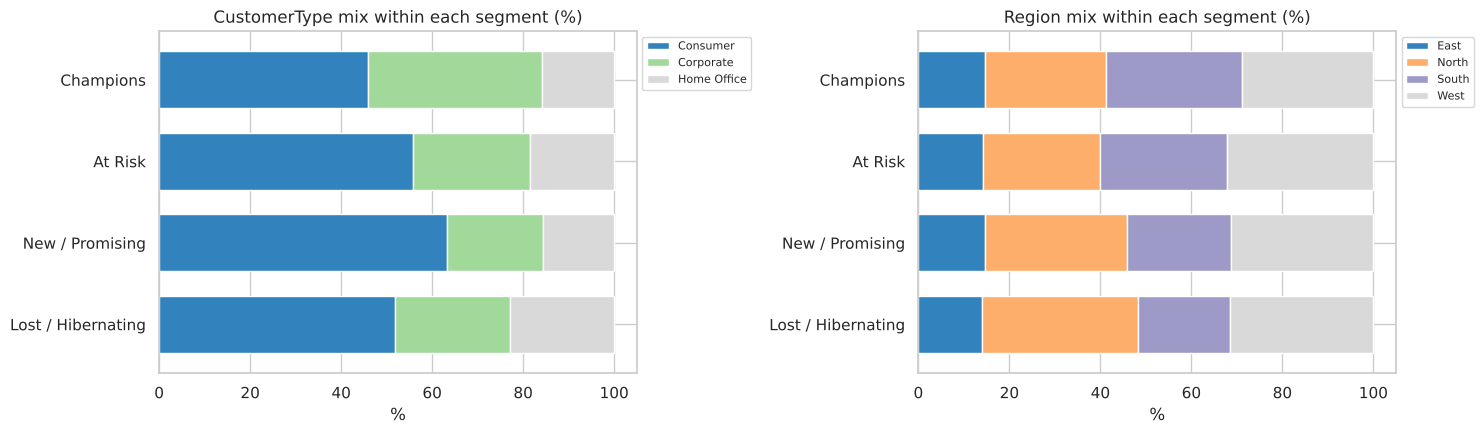

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in zip(axes, ["CustomerType", "Region"]):
    ct = pd.crosstab(cust["SegmentName"], cust[col], normalize="index").reindex(ORDER) * 100
    ct.plot(kind="barh", stacked=True, ax=ax, colormap="tab20c", width=.7)
    ax.set_title(f"{col} mix within each segment (%)"); ax.set_xlabel("%"); ax.set_ylabel(""); ax.invert_yaxis()
    ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

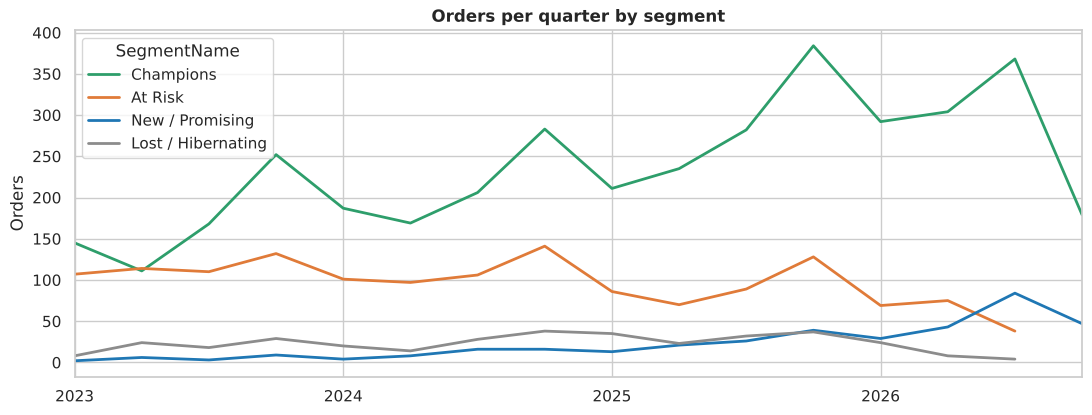

In [17]:
# Monthly order activity by segment shows when each group was actually buying
seg_month = df.merge(cust[["SegmentName"]], left_on="Customer ID", right_index=True) \
              .groupby([pd.Grouper(key="Order Date", freq="QE"), "SegmentName"])["Order ID"].nunique().unstack()[ORDER]
ax = seg_month.plot(figsize=(13, 4.5), color=[PALETTE[s] for s in ORDER], linewidth=2)
ax.set_title("Orders per quarter by segment", fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("Orders")
plt.show()

In [18]:
# Key numbers used in the insights below
tot_rev = cust["Monetary"].sum()
champ = profile.loc["Champions"]; risk = profile.loc["At Risk"]
new = profile.loc["New / Promising"]; lost = profile.loc["Lost / Hibernating"]
corp_share = pd.crosstab(cust["SegmentName"], cust["CustomerType"], normalize="index").loc["Champions", "Corporate"] * 100
print(f"Champions: {champ['% Customers']:.1f}% of customers -> {champ['% Revenue']:.1f}% of revenue, "
      f"median {champ['Median_Orders']:.0f} orders, AOV Rs {champ['Avg_Order_Value']:,.0f}, Corporate share {corp_share:.0f}%")
print(f"At Risk:   {risk['% Customers']:.1f}% of customers, {risk['% Revenue']:.1f}% of revenue, "
      f"Rs {risk['Total_Revenue']:,.0f} historical spend, median {risk['Median_Recency_days']:.0f} days since last order")
print(f"New:       {new['% Customers']:.1f}% of customers, median recency {new['Median_Recency_days']:.0f} days, "
      f"median {new['Median_Orders']:.0f} orders")
print(f"Lost:      {lost['% Customers']:.1f}% of customers but only {lost['% Revenue']:.1f}% of revenue, "
      f"median {lost['Median_Orders']:.0f} order, {lost['Median_Recency_days']:.0f} days inactive")
print("Avg discount by segment (%):", (profile["Avg_Discount"] * 100).round(1).to_dict())
print("Profit margin by segment (%):", profile["Profit_Margin_%"].round(1).to_dict())

Champions: 25.7% of customers -> 65.0% of revenue, median 17 orders, AOV Rs 6,527, Corporate share 38%
At Risk:   28.7% of customers, 25.9% of revenue, Rs 9,350,632 historical spend, median 330 days since last order
New:       16.5% of customers, median recency 44 days, median 3 orders
Lost:      29.2% of customers but only 3.9% of revenue, median 1 order, 621 days inactive
Avg discount by segment (%): {'Champions': 9.1, 'At Risk': 9.5, 'New / Promising': 9.5, 'Lost / Hibernating': 9.7}
Profit margin by segment (%): {'Champions': 22.1, 'At Risk': 21.4, 'New / Promising': 21.6, 'Lost / Hibernating': 24.5}


## 8. Key insights

1. **Revenue is highly concentrated.** **Champions** are only **25.7% of customers but generate 65.0% of revenue**. They order often (median 17 orders), bought recently (median ~26 days ago), and are the most Technology-heavy group (44.6% of their spend). Corporate buyers are over-represented here (38% vs 28% across all customers).
2. **At Risk is the biggest opportunity.** These **190 customers (28.7%)** have brought in **25.9% of all revenue (about ₹93.5 lakh)** and have the **highest average order value (₹6,861)**, but their median last order was **330 days ago**. They were valuable customers who are drifting away.
3. **New / Promising customers are fresh but shallow.** They make up **16.5%** of customers, last ordered a median of **44 days ago**, and have placed only **3 orders** each. Their spend leans towards Furniture and Office Supplies (about 69% combined) rather than Technology.
4. **Lost / Hibernating customers add little value.** They are **29.2% of customers but only 3.9% of revenue**. Most bought **once** and have been inactive for a median of **621 days**.
5. **Discounts don't explain loyalty.** Average discount use is almost the same in every segment (9–10%). What separates the segments is how often and how recently customers buy, not how much discount they get.

## 9. Recommendations

| Segment | Goal | Suggested actions |
|---|---|---|
| **Champions** | Retain and grow | Loyalty or VIP programme, early access to new Technology products, a dedicated account manager for Corporate buyers. No blanket discounts needed. |
| **At Risk** | Win back | Personalised "we miss you" campaigns, a time-limited offer on categories they bought before, a feedback survey to find out why they left. Top priority because of their high past value. |
| **New / Promising** | Convert to repeat buyers | Onboarding emails, second-purchase incentives, cross-selling Technology accessories alongside the Furniture they already buy. |
| **Lost / Hibernating** | Low-cost reactivation | Only cheap automated channels (emails, festive-season offers before Oct–Nov). Don't spend heavily here. |

**Limitations:** RFM uses only purchase history. Adding features such as product returns, website activity or demographics could produce richer segments. Clusters should also be re-run periodically as customers move between segments.

In [19]:
out = cust[["CustomerType", "Region", "Recency", "Frequency", "Monetary", "AvgOrderValue", "ProfitMargin", "SegmentName"]]
out.to_csv("customer_segments.csv")
print(f"Saved customer_segments.csv with {len(out)} customers")
out["SegmentName"].value_counts()

Saved customer_segments.csv with 662 customers


SegmentName
Lost / Hibernating    193
At Risk               190
Champions             170
New / Promising       109
Name: count, dtype: int64